<a href="https://colab.research.google.com/github/sumeyyeozturk0/MLP-Digit-Recognition/blob/main/DerinOgrenme_Odev1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [27]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

In [28]:
train_size = 54000
val_size = 6000
train_data, val_data = random_split(train_dataset, [train_size, val_size])

batch_size = 64
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [29]:
import torch.nn as nn
import torch.nn.functional as F

class MLPModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(784, 128)
        self.layer2 = nn.Linear(128, 64)
        self.layer3 = nn.Linear(64, 10)

    def forward(self, x):
        x = x.view(x.shape[0], -1)
        x = F.relu(self.layer1(x))
        x = F.relu(self.layer2(x))
        x = self.layer3(x)

        return x

In [30]:
import torch.optim as optim
model = MLPModel()

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(), lr=0.001)

In [31]:
train_losses = []
val_losses = []
val_accuracies = []

epochs = 5

for epoch in range(epochs):
    model.train()
    for images, labels in train_loader:
        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    model.eval()
    dogru_bilinen = 0
    toplam = 0

    with torch.no_grad():
        for images, labels in val_loader:
            outputs = model(images)
            val_loss = criterion(outputs, labels)

            _, predictions = torch.max(outputs, 1)
            toplam += labels.size(0)
            dogru_bilinen += (predictions == labels).sum().item()

    accuracy = 100 * dogru_bilinen / toplam

    train_losses.append(loss.item())
    val_losses.append(val_loss.item())
    val_accuracies.append(accuracy)

    print(f"Epoch {epoch+1} tamamlandı! Doğrulama Başarısı: %{accuracy:.2f}")

Epoch 1 tamamlandı! Doğrulama Başarısı: %91.98
Epoch 2 tamamlandı! Doğrulama Başarısı: %94.50
Epoch 3 tamamlandı! Doğrulama Başarısı: %95.35
Epoch 4 tamamlandı! Doğrulama Başarısı: %96.10
Epoch 5 tamamlandı! Doğrulama Başarısı: %96.65


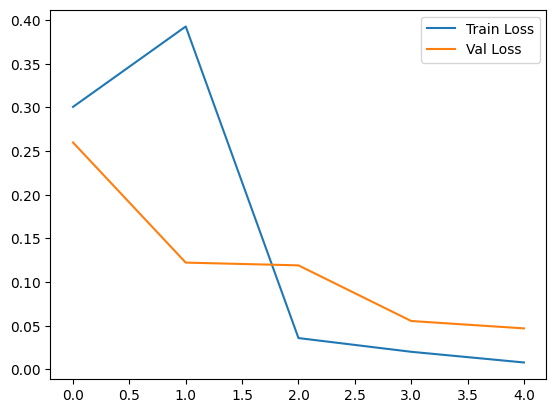

In [32]:
import matplotlib.pyplot as plt

plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')

plt.legend()
plt.show()

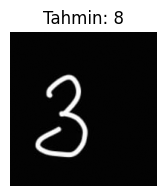

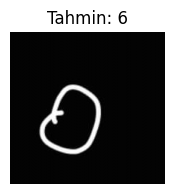

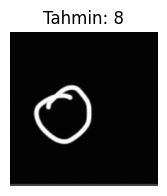

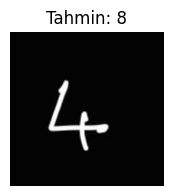

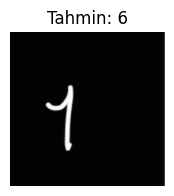

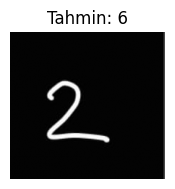

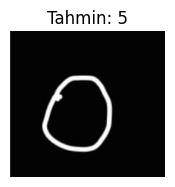

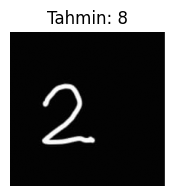

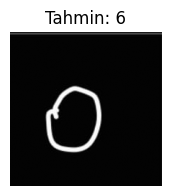

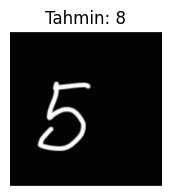

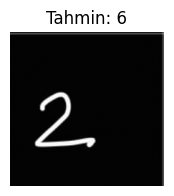

In [33]:
from PIL import Image
import torchvision.transforms as transforms
import torch
import matplotlib.pyplot as plt

donusum = transforms.Compose([
    transforms.Resize((28, 28)),
    transforms.ToTensor()
])

toplam_resim = 11

model.eval()

with torch.no_grad():
    for i in range(1, toplam_resim + 1):
        dosya_adi = f"rakam ({i}).jpeg"

        resim = Image.open(dosya_adi).convert("L")
        resim_tensor = donusum(resim).unsqueeze(0)

        tahmin_puanlari = model(resim_tensor)
        _, nihai_karar = torch.max(tahmin_puanlari, 1)

        plt.figure(figsize=(2,2))
        plt.imshow(resim, cmap="gray")
        plt.title(f"Tahmin: {nihai_karar.item()}")
        plt.axis('off')
        plt.show()